----------------

# Infrared Solar Modules Anomaly Detection & Classification Pipeline

This document provides a comprehensive overview of a computer vision and deep learning project designed to detect, classify, and analyze anomalies in photovoltaic solar cells and modules using thermal imaging.

---

## Table of Contents
1. Project Overview & Architecture
2. Data Preprocessing & Class Imbalance Handling
3. ETL Pipeline & Data Preparation
4. Deep Learning Models (VGG19)
5. Training Strategy & Callbacks
6. Results & Performance Metrics



### Detailed Classification Report (VGG19 Test Evaluation)

| Class | Precision | Recall | F1-Score | Support |
| :--- | :---: | :---: | :---: | :---: |
| **Cell** | 0.326 | 0.323 | 0.324 | 1,038 |
| **Cell-Multi** | 0.316 | 0.202 | 0.246 | 1,016 |
| **Cracking** | 0.716 | 0.497 | 0.587 | 1,057 |
| **Diode** | 0.541 | 0.719 | 0.617 | 1,010 |
| **Diode-Multi** | 0.756 | 0.610 | 0.675 | 977 |
| **Hot-Spot** | 0.422 | 0.698 | 0.526 | 958 |
| **Hot-Spot-Multi** | 0.499 | 0.622 | 0.554 | 940 |
| **No-Anomaly** | 0.369 | 0.525 | 0.434 | 1,023 |
| **Offline-Module** | 0.545 | 0.401 | 0.462 | 1,020 |
| **Shadowing** | 0.569 | 0.494 | 0.529 | 996 |
| **Soiling** | 0.487 | 0.466 | 0.477 | 1,014 |
| **Vegetation** | 0.492 | 0.348 | 0.408 | 983 |
| **Accuracy** | | | **0.490** | **12,032** |
| **Macro Avg** | **0.503** | **0.492** | **0.487** | **12,032** |
| **Weighted Avg** | **0.503** | **0.490** | **0.485** | **12,032** |

#### Key Observations:
* **Best Performing Classes:** The model exhibits strong discriminative ability on structural and electrical defects, achieving the highest precision on **Diode-Multi** (75.6%) and **Cracking** (71.6%), with strong F1-scores on **Diode-Multi** (0.675) and **Diode** (0.617).
* **Thermal Anomalies:** **Hot-Spot** and **Hot-Spot-Multi** show robust recall rates (69.8% and 62.2% respectively), indicating reliable detection of thermal hotspots despite moderate false positives.
* **Challenging Categories:** Fine-grained module-level degradation like **Cell** and **Cell-Multi** present lower F1-scores (0.324 and 0.246), indicating significant visual overlap with other minor thermal patterns.

# Importing

In [4]:
!pip install -q tf2onnx onnx onnxruntime

In [13]:
# Environment setup
import os
import random
import json
import warnings

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')


# Data manipulation and ETL
import numpy as np
import pandas as pd
from PIL import Image


# Learning and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score
from imblearn.over_sampling import RandomOverSampler


# Deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications import VGG19


# Visualization
import matplotlib.pyplot as plt
import seaborn as sns


# Model export and conversion
import tf2onnx
import onnx

# Setup Global Vars

In [6]:
# Set global seed
Seed = 42
os.environ['PYTHONHASHSEED'] = str(Seed)
random.seed(Seed)
np.random.seed(Seed)
tf.random.set_seed(Seed)

# Handling Class Imbalance

In [7]:
base_dir = "/kaggle/input/datasets/ranaahmedelmaghraby/infrared-solar-modules/InfraredSolarModules"
json_path = os.path.join(base_dir, "module_metadata.json")
dst_dir = "/kaggle/working/Solar_Dataset_Balanced_OS"

# Read metadata JSON
with open(json_path, 'r') as f:
    metadata = json.load(f)


# Extract image IDs and their corresponding anomaly classes
image_ids = list(metadata.keys())
classes_list = [metadata[img_id]['anomaly_class'] for img_id in image_ids]



# Encode labels for the oversampler
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(classes_list)



# Dummy array of indices to apply RandomOverSampler on image IDs
indices = np.arange(len(image_ids)).reshape(-1, 1)

ros = RandomOverSampler(random_state=Seed)
indices_resampled, y_resampled = ros.fit_resample(indices, y_encoded)
indices_resampled = indices_resampled.flatten()



# Map back resampled indices to image IDs (some IDs will be repeated to balance classes)
balanced_image_ids = [image_ids[idx] for idx in indices_resampled]
balanced_classes = label_encoder.inverse_transform(y_resampled)
print(f"Total images after RandomOverSampler: {len(balanced_image_ids)}")



# Create subfolders and link images (Symlinks)
for i, img_id in enumerate(balanced_image_ids):
    info = metadata[img_id]
    cls_name = balanced_classes[i]  # Get the balanced class name
    src_path = os.path.join(base_dir, info['image_filepath'])
    
    cls_folder = os.path.join(dst_dir, cls_name)
    os.makedirs(cls_folder, exist_ok=True)
    
    # Use unique filenames for symlinks since some image IDs might be repeated due to oversampling
    dst_path = os.path.join(cls_folder, f"{img_id}_{i}.jpg")
    if not os.path.exists(dst_path):
        os.symlink(src_path, dst_path)
        


print("Balanced dataset folders created successfully!")
print("Classes folders and their file counts:")
for cls in sorted(os.listdir(dst_dir)):
    print(f"- {cls}: {len(os.listdir(os.path.join(dst_dir, cls)))} files")

Total images after RandomOverSampler: 120000
Balanced dataset folders created successfully!
Classes folders and their file counts:
- Cell: 10000 files
- Cell-Multi: 10000 files
- Cracking: 10000 files
- Diode: 10000 files
- Diode-Multi: 10000 files
- Hot-Spot: 10000 files
- Hot-Spot-Multi: 10000 files
- No-Anomaly: 10000 files
- Offline-Module: 10000 files
- Shadowing: 10000 files
- Soiling: 10000 files
- Vegetation: 10000 files


# Setup for Model

In [18]:
data_dir = dst_dir
Image_size = (128, 128)
Batch_size = 64

# ETL Pipeline

In [20]:
# Extract data -> Split into 80% Train and 20% Temp (Val + Test)
train_data_raw, temp_data_raw = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    subset="both",
    validation_split=0.2,
    image_size=Image_size,
    batch_size=Batch_size,
    seed=Seed,
    shuffle=True,
    color_mode="rgb",  
    label_mode="categorical" ) 



# Save class names before transformations
class_names = train_data_raw.class_names
print(f"\nClasses ({len(class_names)}): {class_names}")



# Split the 20% Temp into 10% Validation and 10% Test
temp_batches = tf.data.experimental.cardinality(temp_data_raw)
val_data_raw  = temp_data_raw.take(temp_batches // 2)
test_data_raw = temp_data_raw.skip(temp_batches // 2)

print(f"Train Batches: {tf.data.experimental.cardinality(train_data_raw)}")
print(f"Val Batches  : {tf.data.experimental.cardinality(val_data_raw)}")
print(f"Test Batches : {tf.data.experimental.cardinality(test_data_raw)}")



# Normalization [0, 1] on train, val, and test
train_data_norm = train_data_raw.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y))
val_data_norm   = val_data_raw.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y))
test_data_norm  = test_data_raw.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y))



# Data augmentation layer
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=Seed),
    tf.keras.layers.RandomRotation(0.05, seed=Seed),
])



# Apply Augmentation on Train only
train_data_aug = train_data_norm.map(lambda x, y: (data_augmentation(x, training=True), y))



# Prefetch to make CPU and GPU work in parallel
train_data_norm = train_data_norm.prefetch(tf.data.AUTOTUNE)
val_data_norm   = val_data_norm.prefetch(tf.data.AUTOTUNE)
test_data_norm  = test_data_norm.prefetch(tf.data.AUTOTUNE)
train_data_aug  = train_data_aug.prefetch(tf.data.AUTOTUNE)

Found 120000 files belonging to 12 classes.
Using 96000 files for training.
Using 24000 files for validation.

Classes (12): ['Cell', 'Cell-Multi', 'Cracking', 'Diode', 'Diode-Multi', 'Hot-Spot', 'Hot-Spot-Multi', 'No-Anomaly', 'Offline-Module', 'Shadowing', 'Soiling', 'Vegetation']
Train Batches: 1500
Val Batches  : 187
Test Batches : 188


# Show Data

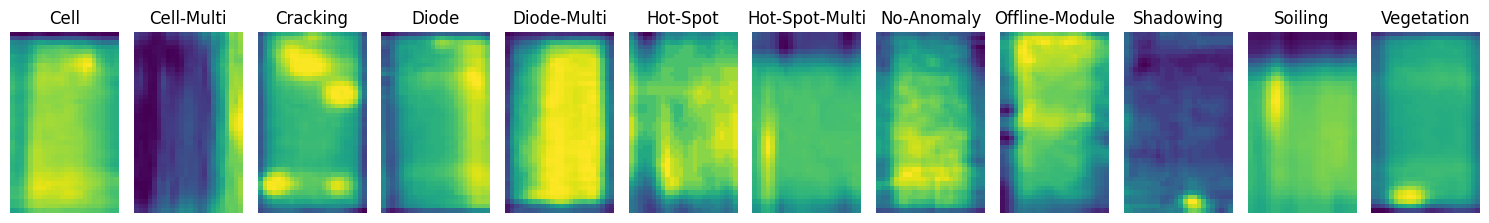

In [12]:
dataset_dir = "/kaggle/working/Solar_Dataset_Balanced_OS"
classes = sorted(os.listdir(dataset_dir))

plt.figure(figsize=(15, 3))
for i, c in enumerate(classes):
    cls_folder = os.path.join(dataset_dir, c)
    img_name = os.listdir(cls_folder)[0]
    p = os.path.join(cls_folder, img_name)
    
    plt.subplot(1, len(classes), i + 1)
    plt.imshow(Image.open(p))
    plt.title(c)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Bulding VGG19 Model

In [21]:
# Load VGG19 Pretrained Base
base_model = VGG19(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze the base layers to retain learned features
base_model.trainable = False

# Build the Model Architecture
inputs = layers.Input(shape=(128, 128, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

vgg19_model = models.Model(inputs=inputs, outputs=outputs, name="VGG19_Solar_Classifier")

# Compile the Model
vgg19_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

vgg19_model.summary()

Model: "VGG19_Solar_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 4, 4, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │         3,084 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,159,820 (76.90 MB)

 Trainable params: 134,924 (527.05 KB)

 Non-trainable params: 20,024,896 (76.39 MB)

In [22]:
# Callbacks and Training
my_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath="/kaggle/working/best_solar_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [23]:
# Train the Model
epochs = 20

history_vgg19 = vgg19_model.fit(
    train_data_aug,
    validation_data=val_data_norm,
    epochs=epochs,
    callbacks=my_callbacks
)



Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.2222 - loss: 2.3152
Epoch 1: val_loss improved from None to 2.09116, saving model to /kaggle/working/best_solar_cnn.keras

Epoch 1: finished saving model to /kaggle/working/best_solar_cnn.keras
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 332s 212ms/step - accuracy: 0.2779 - loss: 2.1485 - val_accuracy: 0.2749 - val_loss: 2.0912 - learning_rate: 1.0000e-04
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.3550 - loss: 1.9352
Epoch 2: val_loss improved from 2.09116 to 1.89349, saving model to /kaggle/working/best_solar_cnn.keras

Epoch 2: finished saving model to /kaggle/working/best_solar_cnn.keras
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 321s 214ms/step - accuracy: 0.3664 - loss: 1.9009 - val_accuracy: 0.3707 - val_loss: 1.8935 - learning_rate: 1.0000e-04
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.3902 - loss: 1.8359
Epoch 3: val_loss did not improve from 1.89349
1500/1500 ━━━━━━━━━━━━━━━━━━━━

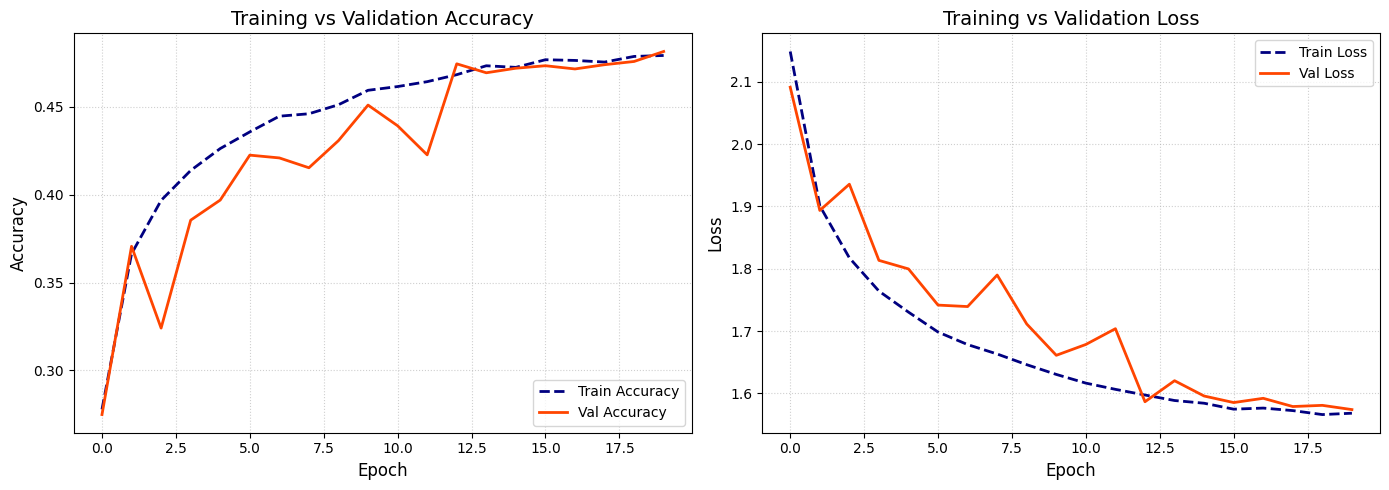

In [25]:
plt.figure(figsize=(14, 5))

# Accuracy Chart
plt.subplot(1, 2, 1)
plt.plot(history_vgg19.history['accuracy'], label='Train Accuracy', color='navy', linestyle='--', linewidth=2)
plt.plot(history_vgg19.history['val_accuracy'], label='Val Accuracy', color='orangered', linestyle='-', linewidth=2)
plt.title('Training vs Validation Accuracy', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# Loss Chart
plt.subplot(1, 2, 2)
plt.plot(history_vgg19.history['loss'], label='Train Loss', color='navy', linestyle='--', linewidth=2)
plt.plot(history_vgg19.history['val_loss'], label='Val Loss', color='orangered', linestyle='-', linewidth=2)
plt.title('Training vs Validation Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [26]:
# Evaluate on Test Data
test_loss, test_accuracy = vgg19_model.evaluate(test_data_norm)
print(f"\nVGG19 Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"VGG19 Test Loss: {test_loss:.4f}")

188/188 ━━━━━━━━━━━━━━━━━━━━ 34s 165ms/step - accuracy: 0.4899 - loss: 1.5384

VGG19 Test Accuracy: 48.99%
VGG19 Test Loss: 1.5384


In [28]:
y_true = []
y_pred = []

for images, labels in test_data_norm:
    preds = vgg19_model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))
    

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [29]:
print("Detailed Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

Detailed Classification Report:
                precision    recall  f1-score   support

          Cell      0.326     0.323     0.324      1038
    Cell-Multi      0.316     0.202     0.246      1016
      Cracking      0.716     0.497     0.587      1057
         Diode      0.541     0.719     0.617      1010
   Diode-Multi      0.756     0.610     0.675       977
      Hot-Spot      0.422     0.698     0.526       958
Hot-Spot-Multi      0.499     0.622     0.554       940
    No-Anomaly      0.369     0.525     0.434      1023
Offline-Module      0.545     0.401     0.462      1020
     Shadowing      0.569     0.494     0.529       996
       Soiling      0.487     0.466     0.477      1014
    Vegetation      0.492     0.348     0.408       983

      accuracy                          0.490     12032
     macro avg      0.503     0.492     0.487     12032
  weighted avg      0.503     0.490     0.485     12032



In [ ]:
# Save VGG19 CNN in Keras format
vgg19_model.save("/kaggle/working/VGG19_solar_cnn.keras")

# Convert VGG19 CNN to ONNX with the correct expected shape (128, 128, 3)
input_signature = [tf.TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name="input")]
onnx_model, _ = tf2onnx.convert.from_keras(vgg19_model, input_signature=input_signature, opset=15)

onnx.save(onnx_model, "/kaggle/working/VGG19_solar_cnn.onnx")

vgg19_model.save("/kaggle/working/VGG19_solar_cnn.h5")

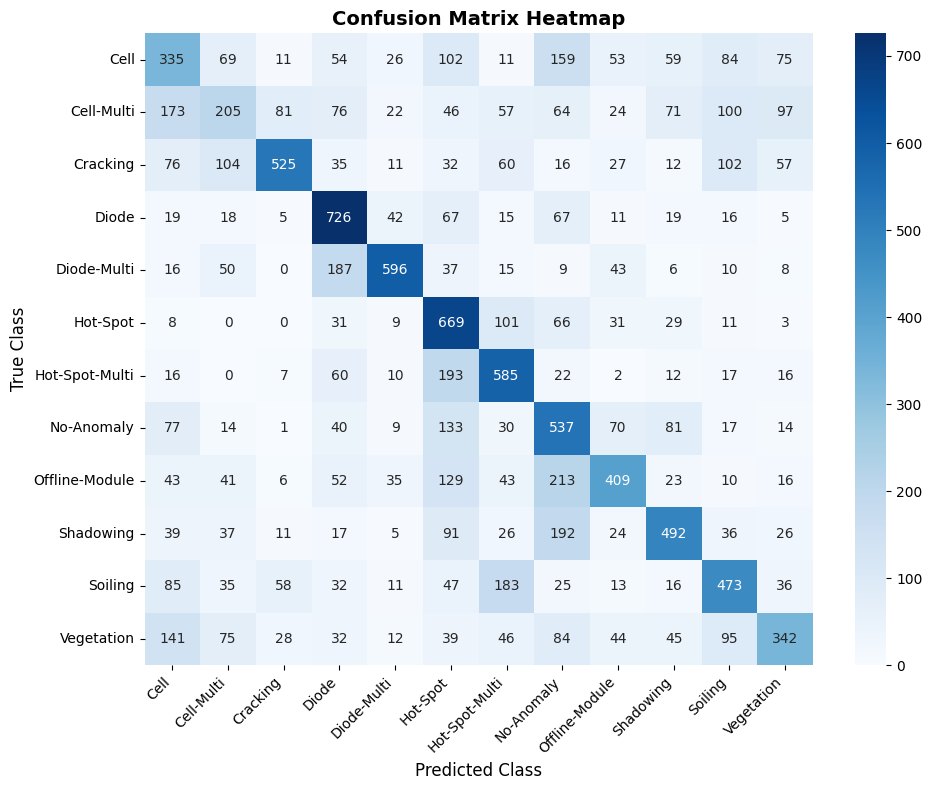

In [31]:
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix Heatmap', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Class', fontsize=12)
plt.ylabel('True Class', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()